# SEGTHOR Results

Dice: higher is better. HD95 is in mm; absolute RVD: lower is better. Tables show mean +/- sample SD across seeds, not confidence intervals. Seeds share validation patients.

`segthor/` uses anisotropic sampling; `segthor_new/` uses isotropic sampling. Phases are assigned by explicit run-name prefixes, with the most specific prefix first. Loss versions and training budgets differ between phases.

Baselines 0/1/2, Phase 6c and final runs use the current heart-largest / aorta-0.25-mL policy. The reused Phase 6b one-slice seed-42 result also uses the current policy, as confirmed by the group. Other runs use older postprocessing. Compare postprocessed scores only within the same policy. Raw `metrics_3d_raw` bundles take priority over legacy metric directories.


In [1]:
from pathlib import Path
import os
import re
import warnings
import numpy as np
import pandas as pd
from IPython.display import display

REPO = Path.cwd() if (Path.cwd() / "results").is_dir() else Path.cwd().parent
ROOTS = {"anisotropic": REPO / "results/segthor", "isotropic": REPO / "results/segthor_new"}
ORGANS = ["esophagus", "heart", "trachea", "aorta"]
METRICS = ["dice", "hd95", "abs_rvd"]
SEEDS = [42, 123, 2026]
PHASES = {
    "baseline": ("Baselines", "baseline_"),
    "phase1": ("Phase 1: losses", "phase1_loss_"),
    "phase1b": ("Phase 1b: weighted CE", "phase1b_wce_"),
    "phase1c": ("Phase 1c: boundary / sqrt Dice", "phase1c_boundary_"),
    "phase2": ("Phase 2: loss confirmation", "phase2_loss_"),
    "phase3a": ("Phase 3a: Adam / AdamW", "phase3a_opt_"),
    "phase3b": ("Phase 3b: SGD / RMSprop", "phase3b_opt_"),
    "phase4": ("Phase 4: 50 epochs / corrected weighted Dice", "phase4_opt_"),
    "phase5": ("Phase 5 / 5c: augmentation", "phase5_aug_"),
    "phase5b": ("Phase 5b: component ablation", "phase5b_aug_"),
    "phase6": ("Phase 6: context, revised CE / Dice", "phase6_context_"),
    "phase6b": ("Phase 6b: 2D, stable CE / historical Dice", "phase6b_context_"),
    "phase6c": ("Phase 6c: 2.5D, stable CE / historical Dice", "phase6c_context_"),
    "phase7": ("Phase 7: final confirmation", "final_"),
}
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)

def average(values):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return float(np.nanmean(values))

def formatted(values, decimals=4):
    values = pd.Series(values).dropna().astype(float)
    if values.empty:
        return "-"
    if len(values) == 1:
        return f"{values.iloc[0]:.{decimals}f}"
    spread = values.std(ddof=1) if np.isfinite(values).all() else np.nan
    return f"{values.mean():.{decimals}f} +/- {spread:.{decimals}f}"

def metrics_from_folder(folder):
    scores = {}
    for filename, metric in [("dice", "dice"), ("hd95", "hd95"), ("rvd", "abs_rvd")]:
        path = folder / f"{filename}.npz"
        if not path.exists():
            continue
        with np.load(path) as bundle:
            if not bundle.files:
                continue
            values = np.stack([bundle[p] for p in bundle.files])[:, 1:5]
            if metric == "abs_rvd":
                values = np.abs(values)
            scores[metric] = average(values)
            for index, organ in enumerate(ORGANS):
                scores[f"{metric}_{organ}"] = average(values[:, index])
            scores["patients"] = len(bundle.files)
    return scores

def parse_run(name):
    match = re.fullmatch(r"(.+)_s(\d+)", name)
    if not match:
        return None
    body, seed = match.group(1), int(match.group(2))
    for phase, (_, prefix) in sorted(PHASES.items(), key=lambda item: len(item[1][1]), reverse=True):
        if body.startswith(prefix):
            config = body[len(prefix):]
            if phase == "baseline":
                if config not in {"0", "1", "2"}:
                    return None
                config = f"baseline_{config}"
            if phase in {"phase3a", "phase3b"}:
                config = re.sub(r"_\d+ep$", "", config)
            return phase, config, seed
    return None

rows = []
curves = {}
for dataset, root in ROOTS.items():
    if not root.exists():
        continue
    for folder in sorted(root.iterdir()):
        parsed = parse_run(folder.name) if folder.is_dir() else None
        if parsed is None:
            continue
        phase, config, seed = parsed
        base = dict(dataset=dataset, phase=phase, config=config, seed=seed,
                    run=folder.name, path=folder, reused=False,
                    postprocessing_policy="current" if phase in {"baseline", "phase6c", "phase7"}
                    or folder.name == "phase6b_context_enet_1slice_25ep_ce_dice_s42" else "older",
                    validated_epochs=np.nan, best_epoch=np.nan, final_dice=np.nan,
                    dice_2d_selected=np.nan)
        curve_path = folder / "dice_3d_val.npy"
        if curve_path.exists():
            arr = np.load(curve_path)
            curve = np.array([average(v) for v in arr[:, 1:5]])
            valid = np.flatnonzero(np.isfinite(curve))
            if len(valid):
                base.update(validated_epochs=len(valid), best_epoch=int(np.nanargmax(curve)),
                            final_dice=float(curve[valid[-1]]))
                curves[(dataset, folder.name)] = arr
        epoch_file = folder / "best_epoch.txt"
        if epoch_file.exists():
            match = re.search(r"epoch[ =:]+(\d+)", epoch_file.read_text())
            if match:
                base["best_epoch"] = int(match.group(1))
        dice_2d_path = folder / "dice_val.npy"
        if dice_2d_path.exists() and pd.notna(base["best_epoch"]):
            dice_2d = np.load(dice_2d_path, mmap_mode="r")
            selected_epoch = int(base["best_epoch"])
            if 0 <= selected_epoch < len(dice_2d):
                base["dice_2d_selected"] = average(dice_2d[selected_epoch, ..., 1:5])
        for stage, candidates in {
            "raw": (["metrics_3d_raw", "metrics3d", "metrics_3d"] if phase == "baseline"
                    else ["metrics_3d_raw", "metrics_3d", "metrics3d"]),
            "post": ["metrics_3d_postprocessed"],
        }.items():
            metric_folder = next((folder / c for c in candidates if (folder / c).is_dir()), None)
            if metric_folder is None:
                continue
            scores = metrics_from_folder(metric_folder)
            if scores:
                rows.append({**base, "stage": stage, "metric_source": str(metric_folder.relative_to(REPO)), **scores})
data = pd.DataFrame(rows)
if data.empty:
    raise ValueError("No metric bundles found under results/segthor or results/segthor_new")
for metric in METRICS:
    for column in [metric, *[f"{metric}_{o}" for o in ORGANS]]:
        if column not in data:
            data[column] = np.nan

# Screening runs are reused only when the confirmation folder is absent.
# These are references, not additional independent training runs.
def reuse_reference(dataset, source_run, target_phase, target_config):
    global data
    source = data[(data["dataset"] == dataset) & (data["run"] == source_run)]
    for _, row in source.iterrows():
        exists = ((data["dataset"] == dataset) & (data["phase"] == target_phase)
                  & (data["config"] == target_config) & (data["seed"] == row["seed"])
                  & (data["stage"] == row["stage"]))
        if exists.any():
            continue
        reference = row.to_dict()
        reference.update(phase=target_phase, config=target_config, reused=True)
        if target_phase == "phase7":
            reference["postprocessing_policy"] = "current"
        data = pd.concat([data, pd.DataFrame([reference])], ignore_index=True)

reuse_reference("anisotropic", "phase1_loss_ce_dice_s42", "phase2", "ce_dice")
reuse_reference("anisotropic", "phase1c_boundary_ce_w_dice_boundary_bw0.001_s42",
                "phase2", "ce_w_dice_boundary_bw0.001")
reuse_reference("isotropic", "phase6b_context_enet_1slice_25ep_ce_dice_s42",
                "phase7", "enet_strong_aug_ce_dice_25ep")
reuse_reference("isotropic", "phase6c_context_enet25d_3s_step1_25ep_ce_dice_s42",
                "phase7", "enet25d_3s_step1_strong_aug_ce_dice_25ep")
# The group confirmed that the reused Phase 6b seed-42 postprocessed bundles
# use the current policy, matching the final confirmation runs.
print("Loaded anisotropic and isotropic results; raw metrics_3d_raw takes priority over legacy folders.")
print("Confirmation tables reuse available screening references without counting copied runs twice.")


Loaded anisotropic and isotropic results; raw metrics_3d_raw takes priority over legacy folders.
Confirmation tables reuse available screening references without counting copied runs twice.


## Each Phase

The existing table layout is preserved. Phase 5 uses only its own runs; its anisotropic no-augmentation result has seed 42 only. Phase 2 and Phase 7 reuse their matching seed-42 screening runs when confirmation copies are absent; these do not count as extra runs. Phase 7 reuses both raw and current-policy postprocessed seed-42 results from Phase 6b (one slice) and Phase 6c (three slices), as confirmed by the group.


In [2]:
def phase_summary(subset):
    result = []
    for config, group in subset.groupby("config", sort=False):
        raw = group[group["stage"] == "raw"]
        post = group[group["stage"] == "post"]
        row = {"configuration": config,
               "raw seeds": ", ".join(map(str, sorted(raw["seed"].unique()))),
               "post seeds": ", ".join(map(str, sorted(post["seed"].unique())))}
        available_2d = group.drop_duplicates("seed").dropna(subset=["dice_2d_selected"])
        row["2D seeds"] = ", ".join(map(str, sorted(available_2d["seed"])))
        row["validation 2D Dice at selected epoch"] = formatted(available_2d["dice_2d_selected"])
        for stage, values in [("raw", raw), ("post", post)]:
            for metric in METRICS:
                row[f"{stage} {metric}"] = formatted(values[metric], 2 if metric == "hd95" else 4)
        result.append(row)
    return pd.DataFrame(result)

for dataset in ROOTS:
    for phase, (title, _) in PHASES.items():
        subset = data[(data["dataset"] == dataset) & (data["phase"] == phase)]
        if not subset.empty:
            print(f"\n{title} | {dataset}")
            display(phase_summary(subset))



Baselines | anisotropic


,configuration,raw seeds,post seeds,2D seeds,validation 2D Dice at selected epoch,raw dice,raw hd95,raw abs_rvd,post dice,post hd95,post abs_rvd
0,baseline_0,"42, 123, 2026","42, 123, 2026","42, 123, 2026",0.8437 +/- 0.0121,0.7158 +/- 0.0215,23.74 +/- 3.65,0.2075 +/- 0.0265,0.7163 +/- 0.0210,20.72 +/- 5.23,0.2092 +/- 0.0275
1,baseline_1,"42, 123, 2026","42, 123, 2026","42, 123, 2026",0.8616 +/- 0.0109,0.7592 +/- 0.0092,17.33 +/- 5.04,0.1506 +/- 0.0374,0.7594 +/- 0.0091,17.18 +/- 4.97,0.1508 +/- 0.0376
2,baseline_2,"42, 123, 2026","42, 123, 2026","42, 123, 2026",0.8631 +/- 0.0033,0.7543 +/- 0.0072,13.33 +/- 3.01,0.1508 +/- 0.0401,0.7549 +/- 0.0067,12.78 +/- 2.52,0.1514 +/- 0.0406



Phase 1: losses | anisotropic


,configuration,raw seeds,post seeds,2D seeds,validation 2D Dice at selected epoch,raw dice,raw hd95,raw abs_rvd,post dice,post hd95,post abs_rvd
0,ce_dice,42,42,42,0.8686,0.7610,13.59,0.1578,0.7458,22.16,0.1801
1,ce,42,42,42,0.8563,0.7604,14.11,0.1222,0.7540,22.50,0.1564
2,ce_w_dice,42,42,42,0.8168,0.7737,27.86,0.1488,0.7795,12.47,0.1460
3,dice,42,42,42,0.3587,0.3959,226.72,686.5271,0.4235,172.01,627.1265
4,w_dice,42,42,42,0.3582,0.4430,189.64,674.7925,0.4687,153.14,664.4856



Phase 1b: weighted CE | anisotropic


...

,configuration,raw seeds,post seeds,2D seeds,validation 2D Dice at selected epoch,raw dice,raw hd95,raw abs_rvd,post dice,post hd95,post abs_rvd
0,enet_1slice_25ep_ce_dice,42,42,42,0.8941,0.8033,11.51,0.0708,0.8033,11.52,0.0707



Phase 6c: 2.5D, stable CE / historical Dice | isotropic


,configuration,raw seeds,post seeds,2D seeds,validation 2D Dice at selected epoch,raw dice,raw hd95,raw abs_rvd,post dice,post hd95,post abs_rvd
0,baseline1_isotropic_25ep_ce,"42, 123, 2026","42, 123, 2026","42, 123, 2026",0.8707 +/- 0.0054,0.7808 +/- 0.0015,15.07 +/- 5.65,0.1283 +/- 0.0331,0.7810 +/- 0.0014,12.25 +/- 0.87,0.1287 +/- 0.0330
1,enet25d_3s_step1_25ep_ce_dice,42,42,42,0.9039,0.8213,9.67,0.0886,0.8214,9.65,0.0885
2,enet25d_5s_step1_25ep_ce_dice,42,42,42,0.9054,0.8173,13.13,0.0836,0.8173,13.13,0.0836
3,enet_1slice_none_25ep_ce_dice,"42, 123, 2026","42, 123, 2026","42, 123, 2026",0.8721 +/- 0.0214,0.7868 +/- 0.0037,16.41 +/- 4.30,0.1280 +/- 0.0132,0.7873 +/- 0.0043,13.58 +/- 0.35,0.1288 +/- 0.0126



Phase 7: final confirmation | isotropic


,configuration,raw seeds,post seeds,2D seeds,validation 2D Dice at selected epoch,raw dice,raw hd95,raw abs_rvd,post dice,post hd95,post abs_rvd
0,enet25d_3s_step1_strong_aug_ce_dice_25ep,"42, 123, 2026","42, 123, 2026","42, 123, 2026",0.9043 +/- 0.0005,0.8212 +/- 0.0006,10.81 +/- 1.54,0.1046 +/- 0.0284,0.8213 +/- 0.0007,10.75 +/- 1.48,0.1047 +/- 0.0283
1,enet_strong_aug_ce_dice_25ep,"42, 123, 2026","42, 123, 2026","42, 123, 2026",0.8701 +/- 0.0498,0.8137 +/- 0.0092,11.88 +/- 2.12,0.1048 +/- 0.0302,0.8138 +/- 0.0092,11.83 +/- 2.02,0.1049 +/- 0.0302


## Per-organ results: baselines 0/1/2, Phase 6c and Phase 7

Raw metrics (`dice`, `hd95`, `abs_rvd`) and current-policy postprocessed metrics (`post_dice`, `post_hd95`, `post_abs_rvd`) appear side by side. Seed lists are reported separately; missing values remain `-`.


In [3]:
def organ_summary(subset):
    result = []
    for config, group in subset.groupby("config", sort=True):
        raw = group[group["stage"] == "raw"]
        post = group[group["stage"] == "post"]
        for organ in ORGANS:
            row = {"configuration": config, "organ": organ,
                   "raw seeds": ", ".join(map(str, sorted(raw["seed"].unique()))),
                   "post seeds": ", ".join(map(str, sorted(post["seed"].unique())))}
            for prefix, values in (("", raw), ("post_", post)):
                for metric in METRICS:
                    row[f"{prefix}{metric}"] = formatted(
                        values[f"{metric}_{organ}"], 2 if metric == "hd95" else 4)
            result.append(row)
    return pd.DataFrame(result)

for phase in ("baseline", "phase6c", "phase7"):
    for dataset in ROOTS:
        subset = data[(data["dataset"] == dataset) & (data["phase"] == phase)]
        if subset.empty:
            continue
        print(f"\n{PHASES[phase][0]} | {dataset} | raw and current postprocessing")
        display(organ_summary(subset))



Baselines | anisotropic | raw and current postprocessing


,configuration,organ,raw seeds,post seeds,dice,hd95,abs_rvd,post_dice,post_hd95,post_abs_rvd
0,baseline_0,esophagus,"42, 123, 2026","42, 123, 2026",0.4889 +/- 0.0179,16.27 +/- 5.95,0.2939 +/- 0.0472,0.4889 +/- 0.0179,16.27 +/- 5.95,0.2939 +/- 0.0472
1,baseline_0,heart,"42, 123, 2026","42, 123, 2026",0.8404 +/- 0.0098,26.75 +/- 19.59,0.1816 +/- 0.0299,0.8423 +/- 0.0120,14.55 +/- 0.98,0.1879 +/- 0.0262
2,baseline_0,trachea,"42, 123, 2026","42, 123, 2026",0.7726 +/- 0.0143,30.53 +/- 27.51,0.1746 +/- 0.0213,0.7726 +/- 0.0143,30.53 +/- 27.51,0.1746 +/- 0.0213
3,baseline_0,aorta,"42, 123, 2026","42, 123, 2026",0.7613 +/- 0.0507,21.40 +/- 6.11,0.1800 +/- 0.0725,0.7615 +/- 0.0509,21.52 +/- 5.52,0.1805 +/- 0.0723
4,baseline_1,esophagus,"42, 123, 2026","42, 123, 2026",0.5342 +/- 0.0021,16.52 +/- 0.69,0.2105 +/- 0.0422,0.5342 +/- 0.0021,16.52 +/- 0.69,0.2105 +/- 0.0422
5,baseline_1,heart,"42, 123, 2026","42, 123, 2026",0.8775 +/- 0.0119,13.99 +/- 2.63,0.1111 +/- 0.0125,0.8779 +/- 0.0116,13.66 +/- 2.24,0.1118 +/- 0.0130
6,baseline_1,trachea,"42, 123, 2026","42, 123, 2026",0.8259 +/- 0.0062,22.39 +/- 21.82,0.1168 +/- 0.0394,0.8259 +/- 0.0062,22.39 +/- 21.82,0.1168 +/- 0.0394
7,baseline_1,aorta,"42, 123, 2026","42, 123, 2026",0.7992 +/- 0.0268,16.42 +/- 7.76,0.1641 +/- 0.0683,0.7996 +/- 0.0268,16.16 +/- 7.57,0.1641 +/- 0.0688
8,baseline_2,esophagus,"42, 123, 2026","42, 123, 2026",0.5286 +/- 0.0258,11.19 +/- 0.89,0.2130 +/- 0.0788,0.5286 +/- 0.0258,11.19 +/- 0.89,0.2130 +/- 0.0788
9,baseline_2,heart,"42, 123, 2026","42, 123, 2026",0.8975 +/- 0.0107,12.67 +/- 2.54,0.0829 +/- 0.0213,0.8994 +/- 0.0091,10.67 +/- 1.66,0.0854 +/- 0.0238



Phase 6c: 2.5D, stable CE / historical Dice | isotropic | raw and current postprocessing


,configuration,organ,raw seeds,post seeds,dice,hd95,abs_rvd,post_dice,post_hd95,post_abs_rvd
0,baseline1_isotropic_25ep_ce,esophagus,"42, 123, 2026","42, 123, 2026",0.5489 +/- 0.0114,13.68 +/- 1.53,0.2128 +/- 0.0840,0.5489 +/- 0.0114,13.68 +/- 1.53,0.2128 +/- 0.0840
1,baseline1_isotropic_25ep_ce,heart,"42, 123, 2026","42, 123, 2026",0.8900 +/- 0.0055,23.34 +/- 19.75,0.0979 +/- 0.0160,0.8907 +/- 0.0048,11.75 +/- 0.48,0.0992 +/- 0.0166
2,baseline1_isotropic_25ep_ce,trachea,"42, 123, 2026","42, 123, 2026",0.8445 +/- 0.0120,11.99 +/- 5.07,0.0861 +/- 0.0271,0.8445 +/- 0.0120,11.99 +/- 5.07,0.0861 +/- 0.0271
3,baseline1_isotropic_25ep_ce,aorta,"42, 123, 2026","42, 123, 2026",0.8397 +/- 0.0094,11.27 +/- 1.99,0.1163 +/- 0.0275,0.8399 +/- 0.0093,11.59 +/- 1.61,0.1166 +/- 0.0276
4,enet25d_3s_step1_25ep_ce_dice,esophagus,42,42,0.6416,8.97,0.0820,0.6416,8.97,0.0820
5,enet25d_3s_step1_25ep_ce_dice,heart,42,42,0.9130,10.85,0.0645,0.9132,10.75,0.0642
6,enet25d_3s_step1_25ep_ce_dice,trachea,42,42,0.8492,13.13,0.1039,0.8492,13.13,0.1039
7,enet25d_3s_step1_25ep_ce_dice,aorta,42,42,0.8815,5.74,0.1039,0.8815,5.74,0.1039
8,enet25d_5s_step1_25ep_ce_dice,esophagus,42,42,0.6389,8.54,0.1162,0.6389,8.54,0.1162
9,enet25d_5s_step1_25ep_ce_dice,heart,42,42,0.9241,7.80,0.0442,0.9241,7.80,0.0442



Phase 7: final confirmation | isotropic | raw and current postprocessing


,configuration,organ,raw seeds,post seeds,dice,hd95,abs_rvd,post_dice,post_hd95,post_abs_rvd
0,enet25d_3s_step1_strong_aug_ce_dice_25ep,esophagus,"42, 123, 2026","42, 123, 2026",0.6471 +/- 0.0123,9.29 +/- 0.59,0.1333 +/- 0.0778,0.6471 +/- 0.0123,9.29 +/- 0.59,0.1333 +/- 0.0778
1,enet25d_3s_step1_strong_aug_ce_dice_25ep,heart,"42, 123, 2026","42, 123, 2026",0.9185 +/- 0.0073,9.71 +/- 1.47,0.0609 +/- 0.0111,0.9189 +/- 0.0076,9.48 +/- 1.72,0.0612 +/- 0.0102
2,enet25d_3s_step1_strong_aug_ce_dice_25ep,trachea,"42, 123, 2026","42, 123, 2026",0.8383 +/- 0.0131,12.99 +/- 0.46,0.1211 +/- 0.0260,0.8383 +/- 0.0131,12.99 +/- 0.46,0.1211 +/- 0.0260
3,enet25d_3s_step1_strong_aug_ce_dice_25ep,aorta,"42, 123, 2026","42, 123, 2026",0.8810 +/- 0.0010,11.23 +/- 7.47,0.1030 +/- 0.0036,0.8810 +/- 0.0010,11.23 +/- 7.47,0.1030 +/- 0.0036
4,enet_strong_aug_ce_dice_25ep,esophagus,"42, 123, 2026","42, 123, 2026",0.6362 +/- 0.0165,10.20 +/- 1.42,0.1306 +/- 0.0667,0.6362 +/- 0.0165,10.20 +/- 1.42,0.1306 +/- 0.0667
5,enet_strong_aug_ce_dice_25ep,heart,"42, 123, 2026","42, 123, 2026",0.9171 +/- 0.0090,8.94 +/- 0.46,0.0584 +/- 0.0119,0.9173 +/- 0.0093,8.76 +/- 0.15,0.0588 +/- 0.0118
6,enet_strong_aug_ce_dice_25ep,trachea,"42, 123, 2026","42, 123, 2026",0.8287 +/- 0.0207,16.65 +/- 6.14,0.1502 +/- 0.0801,0.8287 +/- 0.0207,16.65 +/- 6.14,0.1502 +/- 0.0801
7,enet_strong_aug_ce_dice_25ep,aorta,"42, 123, 2026","42, 123, 2026",0.8730 +/- 0.0095,11.75 +/- 1.18,0.0800 +/- 0.0391,0.8731 +/- 0.0096,11.70 +/- 1.08,0.0799 +/- 0.0392


## Postprocessing Studies

Changes are relative to each study's raw predictions. Seed means are averaged equally. Patient counts and the worst individual Dice change expose incomplete studies and severe regressions; a single-patient study is not a cohort result.

In [4]:
for dataset, root in ROOTS.items():
    if not root.exists():
        continue
    for path in sorted(root.glob("postprocessing_study*/**/per_patient.csv")):
        study = path.parent
        if not path.exists():
            continue
        patients = pd.read_csv(path)
        if patients.empty:
            continue
        if "aorta" in study.name:
            patients = patients[patients["organ"] == "aorta"]
        numeric = ["dice", "hd95_mm", "abs_rvd", "delta_dice", "delta_hd95_mm", "delta_abs_rvd"]
        seed_means = patients.groupby(["policy", "organ", "seed"], as_index=False)[numeric].mean()
        result = []
        for (organ, policy), group in seed_means.groupby(["organ", "policy"], sort=False):
            detail = patients[(patients["organ"] == organ) & (patients["policy"] == policy)]
            result.append({
                "organ": organ, "policy": policy,
                "seeds": ", ".join(map(str, sorted(group["seed"].unique()))),
                "patients": detail["patient"].nunique(),
                **{m: formatted(group[m], 2 if "hd95" in m else 4) for m in numeric},
                "worst patient Dice delta": detail["delta_dice"].min(),
            })
        print(f"\n{study.relative_to(root).as_posix()} | {dataset}")
        display(pd.DataFrame(result))



postprocessing_study_aorta | anisotropic


,organ,policy,seeds,patients,dice,hd95_mm,abs_rvd,delta_dice,delta_hd95_mm,delta_abs_rvd,worst patient Dice delta
0,aorta,aorta_min_0.01ml,"42, 123",5,0.8304 +/- 0.0044,11.82 +/- 0.11,0.1205 +/- 0.0213,0.0000 +/- 0.0000,0.00 +/- 0.00,0.0000 +/- 0.0000,0.000000
1,aorta,aorta_min_0.05ml,"42, 123",5,0.8304 +/- 0.0044,11.82 +/- 0.11,0.1205 +/- 0.0213,0.0000 +/- 0.0000,-0.00 +/- 0.00,-0.0000 +/- 0.0000,0.000000
2,aorta,aorta_min_0.1ml,"42, 123",5,0.8305 +/- 0.0044,11.82 +/- 0.11,0.1205 +/- 0.0213,0.0000 +/- 0.0000,-0.00 +/- 0.00,0.0000 +/- 0.0000,0.000000
3,aorta,aorta_min_0.25ml,"42, 123",5,0.8306 +/- 0.0043,11.74 +/- 0.12,0.1203 +/- 0.0212,0.0002 +/- 0.0001,-0.08 +/- 0.01,-0.0002 +/- 0.0001,0.000000
4,aorta,both,"42, 123",5,0.8308 +/- 0.0008,11.05 +/- 1.54,0.1216 +/- 0.0160,0.0004 +/- 0.0036,-0.77 +/- 1.43,0.0011 +/- 0.0053,-0.041427
5,aorta,fill,"42, 123",5,0.8304 +/- 0.0044,11.82 +/- 0.11,0.1205 +/- 0.0213,0.0000 +/- 0.0000,0.00 +/- 0.00,0.0000 +/- 0.0000,0.000000
6,aorta,largest,"42, 123",5,0.8308 +/- 0.0008,11.05 +/- 1.54,0.1216 +/- 0.0160,0.0004 +/- 0.0036,-0.77 +/- 1.43,0.0011 +/- 0.0053,-0.041427
7,aorta,raw,"42, 123",5,0.8304 +/- 0.0044,11.82 +/- 0.11,0.1205 +/- 0.0213,0.0000 +/- 0.0000,0.00 +/- 0.00,0.0000 +/- 0.0000,0.000000



postprocessing_study_aorta_s2026_patient28 | anisotropic


,organ,policy,seeds,patients,dice,hd95_mm,abs_rvd,delta_dice,delta_hd95_mm,delta_abs_rvd,worst patient Dice delta
0,aorta,aorta_min_0.01ml,2026,1,0.7370,17.84,0.2625,0.0000,0.00,0.0000,0.000000
1,aorta,aorta_min_0.05ml,2026,1,0.7370,17.82,0.2625,0.0000,-0.03,0.0001,0.000031
2,aorta,aorta_min_0.1ml,2026,1,0.7370,17.82,0.2625,0.0000,-0.03,0.0001,0.000031
3,aorta,aorta_min_0.25ml,2026,1,0.7370,17.82,0.2625,0.0000,-0.03,0.0001,0.000031
4,aorta,raw,2026,1,0.7370,17.84,0.2625,0.0000,0.00,0.0000,0.000000



postprocessing_study_phase4 | anisotropic


,organ,policy,seeds,patients,dice,hd95_mm,abs_rvd,delta_dice,delta_hd95_mm,delta_abs_rvd,worst patient Dice delta
0,aorta,both,"42, 123, 2026",5,0.8241 +/- 0.0116,13.80 +/- 4.89,0.1413 +/- 0.0360,-0.0045 +/- 0.0088,1.15 +/- 3.47,0.0142 +/- 0.0231,-0.088056
1,esophagus,both,"42, 123, 2026",5,0.5591 +/- 0.0462,22.70 +/- 19.21,0.2067 +/- 0.0664,-0.0169 +/- 0.0354,7.14 +/- 16.15,0.0330 +/- 0.0833,-0.201543
2,heart,both,"42, 123, 2026",5,0.8809 +/- 0.0083,13.21 +/- 0.73,0.1230 +/- 0.0284,0.0033 +/- 0.0035,-4.59 +/- 4.33,0.0076 +/- 0.0104,-0.003614
3,trachea,both,"42, 123, 2026",5,0.8452 +/- 0.0189,11.28 +/- 2.45,0.1163 +/- 0.0331,0.0077 +/- 0.0149,-3.56 +/- 7.81,-0.0083 +/- 0.0291,-0.027484
4,aorta,fill,"42, 123, 2026",5,0.8286 +/- 0.0044,12.66 +/- 1.45,0.1271 +/- 0.0189,0.0000 +/- 0.0000,0.00 +/- 0.00,0.0000 +/- 0.0000,0.000000
5,esophagus,fill,"42, 123, 2026",5,0.5760 +/- 0.0157,15.56 +/- 4.55,0.1737 +/- 0.0664,0.0000 +/- 0.0000,0.00 +/- 0.00,-0.0000 +/- 0.0000,0.000000
6,heart,fill,"42, 123, 2026",5,0.8777 +/- 0.0114,17.83 +/- 3.71,0.1153 +/- 0.0310,0.0001 +/- 0.0001,0.02 +/- 0.03,-0.0001 +/- 0.0002,-0.000033
7,trachea,fill,"42, 123, 2026",5,0.8376 +/- 0.0089,14.86 +/- 6.20,0.1249 +/- 0.0338,0.0001 +/- 0.0002,0.02 +/- 0.03,0.0002 +/- 0.0004,0.000000
8,aorta,largest,"42, 123, 2026",5,0.8241 +/- 0.0116,13.80 +/- 4.89,0.1413 +/- 0.0360,-0.0045 +/- 0.0088,1.15 +/- 3.47,0.0142 +/- 0.0231,-0.088056
9,esophagus,largest,"42, 123, 2026",5,0.5591 +/- 0.0462,22.70 +/- 19.21,0.2067 +/- 0.0663,-0.0169 +/- 0.0354,7.14 +/- 16.15,0.0330 +/- 0.0833,-0.201543


<a id="phase7-current"></a>

## Current comparison: 3-slice ENet + organ refinement

The three supplied **3-slice ENet checkpoints are frozen**. For each seed, separate trachea, esophagus and heart refiners train on the original 35 training patients. Validation patients remain **01, 13, 22, 28 and 30**, and seeds remain **42, 123 and 2026**. Corrections run trachea → esophagus → heart and protect other organ labels; aorta keeps ENet before optional cleanup.

This is the current matched comparison. The preceding sections retain the original ENet phase and postprocessing results; the refinement gains below use the supplied 3-slice ENet checkpoints.

Every score below uses native patient volumes and the production `metrics_3d.py` definitions. Patients and organs receive equal weight. **± is sample SD across three seed means**, not a confidence interval. Absolute RVD is calculated per patient before averaging. These validation patients have been used repeatedly; they are not an untouched test set.

Run this section independently from its first code cell. It uses the bundled [3-slice ENet snapshot](data/phase7_refinement_results.json), without model weights or cluster access.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

p7_repo = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "notebooks/data/phase7_refinement_results.json").is_file()), None)
if p7_repo is None:
    raise FileNotFoundError("Run from the repository or its notebooks directory.")
p7_path = p7_repo / "notebooks/data/phase7_refinement_results.json"
assert hashlib.sha256(p7_path.read_bytes()).hexdigest() == "9e9e6e4279e542a72866189c213d9700733f1e1be27d4efcdee0716649748ef9", "Snapshot changed: review and regenerate the saved outputs."
p7 = json.loads(p7_path.read_text())
assert p7["status"] == "complete"
p7_rows = pd.DataFrame(p7["patient_metrics"])
p7_organs = ["esophagus", "heart", "trachea", "aorta"]
p7_stages = p7["stages"]
p7_seeds = p7["protocol"]["seeds"]
p7_patients = p7["protocol"]["validation_patients"]
p7_metrics = ["dice", "hd95_mm", "absolute_rvd"]
p7_keys = ["stage", "seed", "patient", "organ"]
p7_expected = pd.MultiIndex.from_product([list(p7_stages), p7_seeds, p7_patients, p7_organs], names=p7_keys)
assert p7_seeds == [42, 123, 2026]
assert p7_patients == ["Patient_01", "Patient_13", "Patient_22", "Patient_28", "Patient_30"]
assert not p7_rows.duplicated(p7_keys).any()
assert p7_rows.set_index(p7_keys).index.sort_values().equals(p7_expected.sort_values())
assert np.isfinite(p7_rows[p7_metrics].to_numpy()).all()
assert p7_rows["dice"].between(0, 1).all()
assert p7_rows[["hd95_mm", "absolute_rvd"]].ge(0).all().all()
p7_seed = p7_rows.groupby(["stage", "seed", "organ"])[p7_metrics].mean()
p7_macro = p7_seed.groupby(["stage", "seed"])[p7_metrics].mean()

def p7_fmt(values, digits=4, signed=False):
    values = pd.Series(values, dtype=float)
    assert len(values) == 3 and values.notna().all()
    sign = "+" if signed else ""
    return f"{values.mean():{sign}.{digits}f} ± {values.std(ddof=1):.{digits}f}"

# Cross-check the portable summary against the patient rows used in this notebook.
for p7_stage in p7_stages:
    for p7_organ in [*p7_organs, "four_organ_mean"]:
        p7_values = (p7_macro.xs(p7_stage) if p7_organ == "four_organ_mean"
                     else p7_seed.xs((p7_stage, p7_organ), level=("stage", "organ")))
        for p7_metric in p7_metrics:
            p7_saved = p7["summary"][p7_stage][p7_organ][p7_metric]
            assert np.isclose(p7_values[p7_metric].mean(), p7_saved["mean"], rtol=0, atol=1e-12)
            assert np.isclose(p7_values[p7_metric].std(ddof=1), p7_saved["sample_sd"], rtol=0, atol=1e-12)
print(f"Loaded {len(p7_stages)} matched pipelines × 3 seeds × 5 patients × 4 organs.")

Loaded 4 matched pipelines × 3 seeds × 5 patients × 4 organs.


In [2]:
p7_raw = p7_macro.xs("raw_enet")
p7_refined = p7_macro.xs("raw_refined")
p7_recheck = p7["phase7_re_evaluation"]["metrics"]
p7_budget = p7["protocol"]["epochs"]
p7_mode = p7["checkpoint_selection"]["42"]["mode"]
p7_selection_text = ("the best native-volume validation Dice checkpoint for each organ"
                     if p7_mode == "best" else "the fixed last completed epoch")
display(Markdown(
    f"**Training and selection.** Each refiner completed **{p7_budget} epochs**; inference uses **{p7_selection_text}**. "
    "The base ENet weights are unchanged. Esophagus and trachea use batch Dice; heart uses per-image Dice, "
    "with masked BCE and deterministic XY flips.\n\n"
    f"**Exact matched baseline.** Re-evaluating the supplied 3-slice ENet checkpoints gives raw Dice "
    f"**{p7_fmt(p7_raw['dice'])}**, compared with the historical rounded **{p7_recheck['dice']['historical_reported_mean']:.4f}**. "
    f"The mean difference is **{p7_recheck['dice']['difference']:+.6f}**. "
    "All refinement gains below use the re-evaluated same-checkpoint baseline. "
    "The historical rounded result remains in the earlier 3-slice ENet tables.\n\n"
    f"**Matched raw result.** Four-organ mean Dice: **{p7_raw['dice'].mean():.4f} → {p7_refined['dice'].mean():.4f}**; "
    f"paired change **{p7_fmt(p7_refined['dice'] - p7_raw['dice'], signed=True)}**. "
    "The spread of a paired change is calculated from the three seed differences."))
display(pd.DataFrame([
    {"Metric": metric, "Historical reported mean": row["historical_reported_mean"],
     "Re-evaluated mean": row["matched_re_evaluation_mean"], "Difference": row["difference"]}
    for metric, row in p7_recheck.items()
]).set_index("Metric"))

**Training and selection.** Each refiner completed **25 epochs**; inference uses **the best native-volume validation Dice checkpoint for each organ**. The base ENet weights are unchanged. Esophagus and trachea use batch Dice; heart uses per-image Dice, with masked BCE and deterministic XY flips.

**Exact matched baseline.** Re-evaluating the supplied 3-slice ENet checkpoints gives raw Dice **0.8213 ± 0.0006**, compared with the historical rounded **0.8212**. The mean difference is **+0.000122**. All refinement gains below use the re-evaluated same-checkpoint baseline. The historical rounded result remains in the earlier 3-slice ENet tables.

**Matched raw result.** Four-organ mean Dice: **0.8213 → 0.8617**; paired change **+0.0404 ± 0.0036**. The spread of a paired change is calculated from the three seed differences.

,Historical reported mean,Re-evaluated mean,Difference
Metric,,,
dice,0.8212,0.821322,0.000122
hd95_mm,10.8100,10.827687,0.017687
absolute_rvd,0.1046,0.104491,-0.000109


### Native-volume scores before and after refinement

The first table uses raw predictions. The second applies the **same previously chosen cleanup** to both pipelines: remove esophagus/trachea components below 1 mL while retaining the largest, leave heart unchanged, and keep the largest aorta component. This differs from the older heart-largest/aorta-0.25-mL policy in the historical notebook sections.

The cleanup comparison is a fixed-policy evaluation on these same validation patients. It is not a new 48-policy search or a new leave-one-patient-out estimate.

In [3]:
def p7_values(stage, organ):
    return (p7_macro.xs(stage) if organ == "four_organ_mean"
            else p7_seed.xs((stage, organ), level=("stage", "organ")))

for p7_first, p7_last, p7_title in [
    ("raw_enet", "raw_refined", "Raw native-volume predictions"),
    ("latest_enet", "latest_refined", "Same fixed cleanup on both pipelines"),
]:
    display(Markdown(f"**{p7_title}**"))
    p7_table = []
    for p7_organ in [*p7_organs, "four_organ_mean"]:
        p7_before, p7_after = p7_values(p7_first, p7_organ), p7_values(p7_last, p7_organ)
        p7_row = {"Organ": p7_organ.replace("_", " ").title()}
        for p7_metric, p7_label, p7_digits in [("dice", "Dice", 4), ("hd95_mm", "HD95 mm", 2), ("absolute_rvd", "Abs RVD", 4)]:
            p7_row["ENet " + p7_label] = p7_fmt(p7_before[p7_metric], p7_digits)
            p7_row["Refined " + p7_label] = p7_fmt(p7_after[p7_metric], p7_digits)
            p7_row["Paired Δ " + p7_label] = p7_fmt(p7_after[p7_metric] - p7_before[p7_metric], p7_digits, signed=True)
        p7_table.append(p7_row)
    display(pd.DataFrame(p7_table).set_index("Organ"))

**Raw native-volume predictions**

,ENet Dice,Refined Dice,Paired Δ Dice,ENet HD95 mm,Refined HD95 mm,Paired Δ HD95 mm,ENet Abs RVD,Refined Abs RVD,Paired Δ Abs RVD
Organ,,,,,,,,,
Esophagus,0.6473 ± 0.0123,0.7467 ± 0.0149,+0.0994 ± 0.0168,9.31 ± 0.65,7.34 ± 0.42,-1.97 ± 0.27,0.1331 ± 0.0773,0.1109 ± 0.0291,-0.0222 ± 0.1041
Heart,0.9186 ± 0.0074,0.9240 ± 0.0081,+0.0055 ± 0.0009,9.72 ± 1.47,8.96 ± 1.37,-0.76 ± 0.46,0.0608 ± 0.0112,0.0565 ± 0.0133,-0.0043 ± 0.0030
Trachea,0.8383 ± 0.0131,0.8948 ± 0.0080,+0.0565 ± 0.0155,13.06 ± 0.33,8.21 ± 2.20,-4.85 ± 2.34,0.1212 ± 0.0259,0.0884 ± 0.0176,-0.0328 ± 0.0101
Aorta,0.8811 ± 0.0009,0.8811 ± 0.0009,+0.0000 ± 0.0000,11.21 ± 7.44,11.21 ± 7.44,+0.00 ± 0.00,0.1029 ± 0.0039,0.1029 ± 0.0039,+0.0000 ± 0.0000
Four Organ Mean,0.8213 ± 0.0006,0.8617 ± 0.0034,+0.0404 ± 0.0036,10.83 ± 1.58,8.93 ± 1.59,-1.90 ± 0.44,0.1045 ± 0.0283,0.0897 ± 0.0081,-0.0148 ± 0.0286


**Same fixed cleanup on both pipelines**

,ENet Dice,Refined Dice,Paired Δ Dice,ENet HD95 mm,Refined HD95 mm,Paired Δ HD95 mm,ENet Abs RVD,Refined Abs RVD,Paired Δ Abs RVD
Organ,,,,,,,,,
Esophagus,0.6481 ± 0.0121,0.7507 ± 0.0175,+0.1026 ± 0.0185,9.12 ± 0.49,6.51 ± 0.41,-2.61 ± 0.80,0.1302 ± 0.0771,0.1105 ± 0.0353,-0.0197 ± 0.1109
Heart,0.9186 ± 0.0074,0.9240 ± 0.0081,+0.0055 ± 0.0009,9.72 ± 1.47,8.96 ± 1.37,-0.76 ± 0.46,0.0608 ± 0.0112,0.0565 ± 0.0133,-0.0043 ± 0.0030
Trachea,0.8414 ± 0.0150,0.8994 ± 0.0105,+0.0580 ± 0.0141,11.63 ± 1.13,5.91 ± 0.98,-5.71 ± 0.56,0.1165 ± 0.0292,0.0877 ± 0.0138,-0.0288 ± 0.0166
Aorta,0.8853 ± 0.0042,0.8853 ± 0.0042,+0.0000 ± 0.0000,5.73 ± 0.40,5.73 ± 0.40,+0.00 ± 0.00,0.0898 ± 0.0143,0.0898 ± 0.0143,+0.0000 ± 0.0000
Four Organ Mean,0.8233 ± 0.0016,0.8649 ± 0.0043,+0.0415 ± 0.0039,9.05 ± 0.22,6.78 ± 0.21,-2.27 ± 0.11,0.0993 ± 0.0291,0.0861 ± 0.0098,-0.0132 ± 0.0318


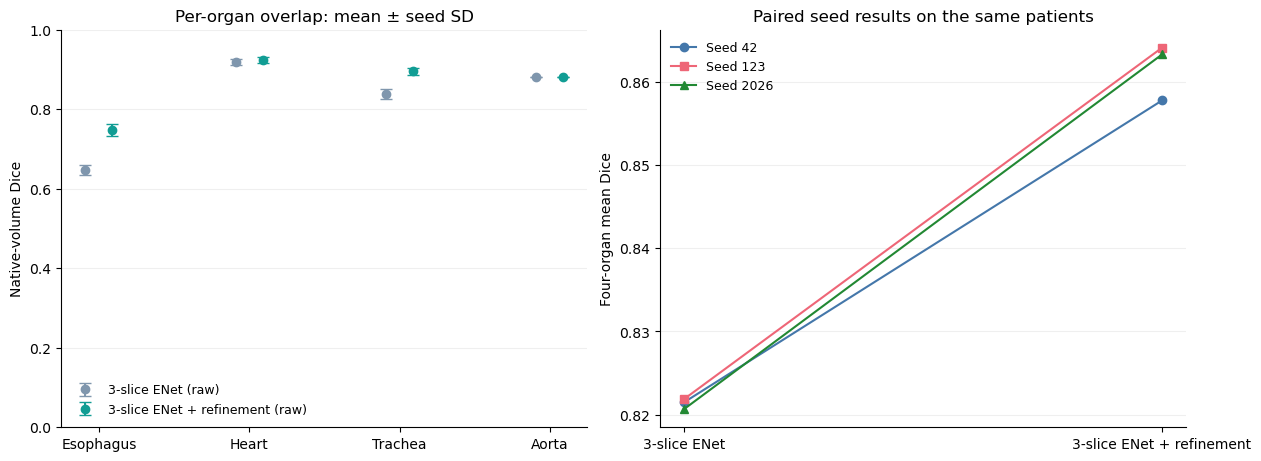

In [4]:
%matplotlib inline
p7_colors = {"raw_enet": "#7f96ad", "raw_refined": "#119d94"}
p7_fig, p7_axes = plt.subplots(1, 2, figsize=(12.5, 4.5), constrained_layout=True)
p7_x = np.arange(len(p7_organs))
for p7_offset, p7_stage in [(-.09, "raw_enet"), (.09, "raw_refined")]:
    p7_stats = p7_seed.xs(p7_stage)["dice"].groupby("organ").agg(["mean", "std"]).reindex(p7_organs)
    p7_axes[0].errorbar(p7_x + p7_offset, p7_stats["mean"], yerr=p7_stats["std"],
                       fmt="o", capsize=4, color=p7_colors[p7_stage], label=p7_stages[p7_stage])
p7_axes[0].set(xticks=p7_x, xticklabels=[o.title() for o in p7_organs],
               ylim=(0, 1), ylabel="Native-volume Dice", title="Per-organ overlap: mean ± seed SD")
p7_axes[0].legend(frameon=False, fontsize=9)
for p7_seed_id, p7_color, p7_marker in zip(p7_seeds, ["#4477aa", "#ee6677", "#228833"], ["o", "s", "^"]):
    p7_pair = [p7_macro.loc[(stage, p7_seed_id), "dice"] for stage in ["raw_enet", "raw_refined"]]
    p7_axes[1].plot([0, 1], p7_pair, marker=p7_marker, color=p7_color, label=f"Seed {p7_seed_id}")
p7_axes[1].set(xticks=[0, 1], xticklabels=["3-slice ENet", "3-slice ENet + refinement"],
               ylabel="Four-organ mean Dice", title="Paired seed results on the same patients")
p7_axes[1].legend(frameon=False, fontsize=9)
for p7_axis in p7_axes:
    p7_axis.grid(axis="y", alpha=.2)
    p7_axis.spines[["top", "right"]].set_visible(False)
plt.show()

### Checkpoint selection and training curves

All refiners train for the stated complete budget. The recorded selection mode determines which checkpoint is used for the final composition. Validation curves show each organ's native-volume selection score; the final multi-organ pipeline is evaluated separately above. The selected checkpoint markers do not provide an independent estimate of generalization.

Selection  Selected epoch  Selection Dice  \
Seed Organ                                                 
42   Trachea        best              23        0.901174   
     Esophagus      best              23        0.729721   
     Heart          best              18        0.918642   
123  Trachea        best               9        0.885784   
     Esophagus      best              24        0.757063   
     Heart          best              18        0.933309   
2026 Trachea        best              20        0.897482   
     Esophagus      best              21        0.753560   
     Heart          best              12        0.920197   

                                                Checkpoint SHA256  
Seed Organ                                                         
42   Trachea    e478cd6ecec7ccfb74b93aad1db211d458a375baa34cc0...  
     Esophagus  4bf7c769b5138120a621087da99c17c2225398614bcf30...  
     Heart      ed0111b8509def04b886e262d44905a6057c95d9df510c...  
123  Trachea    523db754524d65c93b4fbadc4a41c92998e602b58d8be4...  
     Esophagus  c8e475b8f8f4e8a8dcecc8b7192c44fb54cd19db7029a5...  
     Heart      266d870f266e4e3a846fcf1ff1ffdb1802529557a0dd09...  
2026 Trachea    c7018212ac20c81e4abce8fbdebf60334ac6eec4998dae...  
     Esophagus  0de1293d7cb57ead6aa86987b5501450a9a6092b1cff8b...  
     Heart      5858fa402e59268ca894ff9a350768d4766f0cfe4ae02b...

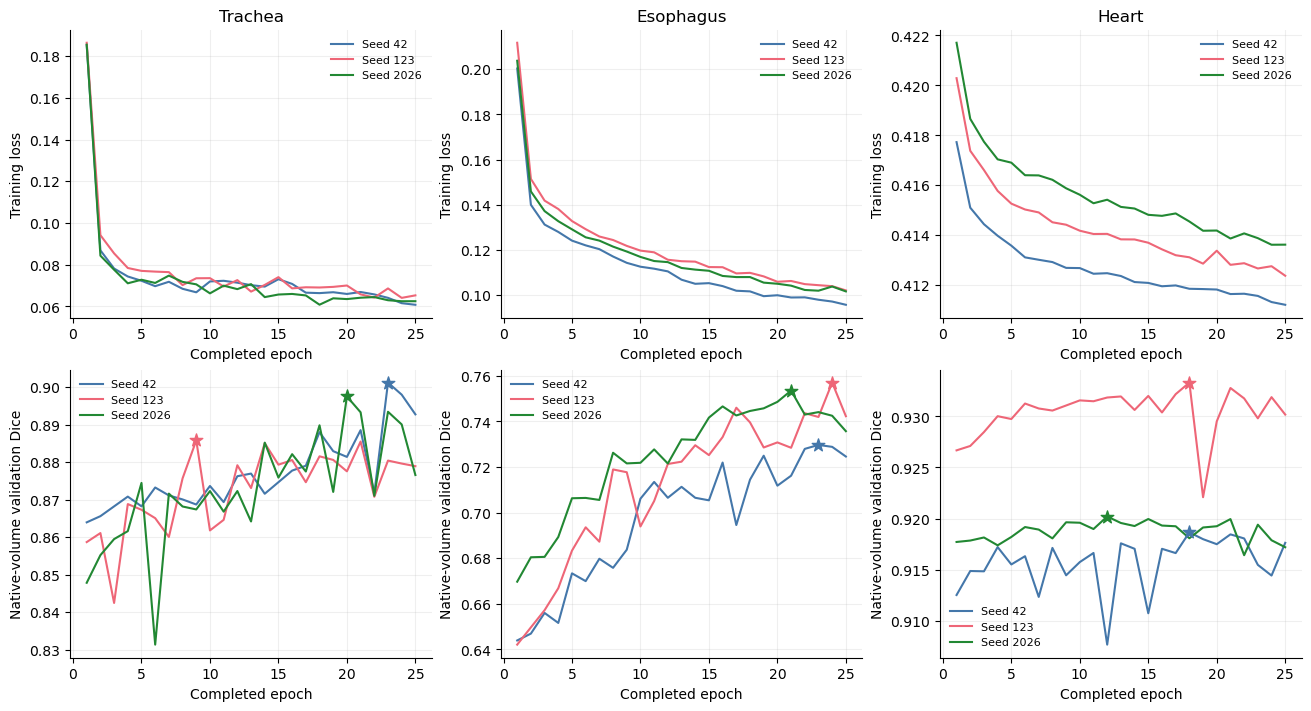

In [5]:
p7_selected_rows = []
for p7_seed_id in p7_seeds:
    p7_selection = p7["checkpoint_selection"][str(p7_seed_id)]
    for p7_organ in ["trachea", "esophagus", "heart"]:
        p7_chosen = p7_selection["organs"][p7_organ]
        p7_selected_rows.append({"Seed": p7_seed_id, "Organ": p7_organ.title(),
            "Selection": p7_selection["mode"], "Selected epoch": p7_chosen.get("selected_epoch"),
            "Selection Dice": p7_chosen.get("validation_dice"),
            "Checkpoint SHA256": p7_chosen["checkpoint"]["sha256"]})
display(pd.DataFrame(p7_selected_rows).set_index(["Seed", "Organ"]))
p7_histories = p7["training_histories"]
assert len(p7_histories) == 9, "All nine completed training histories are needed."
assert len({(h["seed"], h["organ"]) for h in p7_histories}) == 9
assert all([p["epoch"] for p in h["points"]] == list(range(1, p7_budget + 1)) for h in p7_histories)
p7_validation_complete = all(isinstance(point.get("validation_dice"), (int, float))
                             and np.isfinite(point["validation_dice"])
                             for h in p7_histories for point in h["points"])
p7_fig, p7_axes = plt.subplots(2 if p7_validation_complete else 1, 3,
                             figsize=(13, 7 if p7_validation_complete else 3.5), squeeze=False,
                             constrained_layout=True)
p7_seed_colors = dict(zip(p7_seeds, ["#4477aa", "#ee6677", "#228833"]))
for p7_col, p7_organ in enumerate(["trachea", "esophagus", "heart"]):
    for p7_history in p7_histories:
        if p7_history["organ"] != p7_organ:
            continue
        p7_seed_id = p7_history["seed"]
        p7_points = p7_history["points"]
        p7_epochs = [p["epoch"] for p in p7_points]
        p7_losses = [p["loss"]["total"] if isinstance(p.get("loss"), dict)
                     else p.get("loss", p.get("total")) for p in p7_points]
        assert np.isfinite(p7_losses).all()
        p7_axes[0, p7_col].plot(p7_epochs, p7_losses, color=p7_seed_colors[p7_seed_id], label=f"Seed {p7_seed_id}")
        if p7_validation_complete:
            p7_scores = [p["validation_dice"] for p in p7_points]
            p7_axes[1, p7_col].plot(p7_epochs, p7_scores, color=p7_seed_colors[p7_seed_id], label=f"Seed {p7_seed_id}")
            p7_epoch = p7["checkpoint_selection"][str(p7_seed_id)]["organs"][p7_organ].get("selected_epoch")
            if p7_epoch is not None:
                assert 1 <= p7_epoch <= p7_budget
                p7_axes[1, p7_col].scatter([p7_epoch], [p7_scores[p7_epoch - 1]],
                                         marker="*", s=90, color=p7_seed_colors[p7_seed_id], zorder=4)
    p7_axes[0, p7_col].set(title=p7_organ.title(), xlabel="Completed epoch", ylabel="Training loss")
    if p7_validation_complete:
        p7_axes[1, p7_col].set(xlabel="Completed epoch", ylabel="Native-volume validation Dice")
    for p7_axis in p7_axes[:, p7_col]:
        p7_axis.grid(alpha=.2)
        p7_axis.legend(frameon=False, fontsize=8)
        p7_axis.spines[["top", "right"]].set_visible(False)
plt.show()

### Regenerated presentation figures and reproducibility

The presentation graphs use the same patient-level snapshot. The original 3-slice ENet point remains an explicit comparator. The new fixed-cleanup graph reports measured changes under the existing policy; its caption does not repeat the old claim that Dice is unchanged.

- [Final-model Dice comparison (PNG)](../docs/figures/phase7_refinement/slide17_dice.png) · [PDF](../docs/figures/phase7_refinement/slide17_dice.pdf)
- [Boundary and volume metrics (PNG)](../docs/figures/phase7_refinement/slide19_other_metrics.png) · [PDF](../docs/figures/phase7_refinement/slide19_other_metrics.pdf)
- [Summary cards (PNG)](../docs/figures/phase7_refinement/slide18_summary.png) · [PDF](../docs/figures/phase7_refinement/slide18_summary.pdf)
- [Fixed-cleanup effects (PNG)](../docs/figures/phase7_refinement/slide15_fixed_cleanup.png) · [PDF](../docs/figures/phase7_refinement/slide15_fixed_cleanup.pdf)
- [Organ-refinement comparison (PNG)](../docs/figures/phase7_refinement/refinement_comparison.png) · [PDF](../docs/figures/phase7_refinement/refinement_comparison.pdf)
- [Pipeline diagram (PNG)](../docs/figures/phase7_refinement/slide16_pipeline.png) · [PDF](../docs/figures/phase7_refinement/slide16_pipeline.pdf)

[The portable snapshot](data/phase7_refinement_results.json) contains the matched patient metrics, checkpoint hashes, source-report hashes, training histories, and the distinction between historical and re-evaluated 3-slice ENet scores. [The asset manifest](../docs/figures/phase7_refinement/figure_manifest.json) records the rendered graph hashes. Regenerate the report with `experiments/phase7_refinement_report.py` after all three evaluation reports complete.

The [current patient comparison PDF](../docs/research/final_pipeline_comparison.pdf) shows examples from the new 3-slice ENet refinement pipeline. The [current crop coverage audit](../docs/research/crop_failure_examples.pdf) documents its prediction-derived crops.

The gains belong to this matched validation comparison. Reusing these patients for selection means improved scores do not establish performance on independent patients.

The patient-level diagnostics retain both pipeline stages, separately before and after the same cleanup:

- **Raw:** [3-slice ENet](../docs/figures/phase7_refinement/patient_3d_metrics_raw_enet.png) · [3-slice ENet + refinement](../docs/figures/phase7_refinement/patient_3d_metrics_raw_refined.png).
- **Fixed cleanup:** [3-slice ENet](../docs/figures/phase7_refinement/patient_3d_metrics_latest_enet.png) · [3-slice ENet + refinement](../docs/figures/phase7_refinement/patient_3d_metrics_latest_refined.png).

These reuse `plot.py` for Dice-versus-HD95 scatter and signed-RVD distributions. Each organ has 15 seed–patient observations from three seeds on the same five patients; repeated patients are not independent. Signed RVD is preserved from the source measurements, while the comparison tables above use absolute RVD. The [figure index](../docs/figures/phase7_refinement/README.md) records the fresh presentation and remote-main coverage audit.
